In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Defining constants (to be adjusted)
mu_0 = 1
h = 2       # in cm
band_width = 0.5
w_0 = 8     #mean width in no of bands (one band is 0.5 cm)



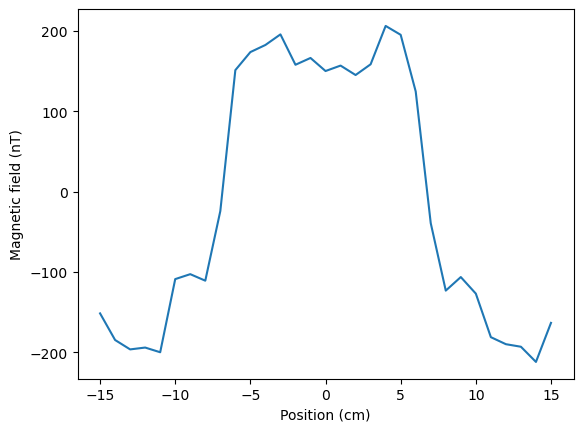

In [41]:
# Reading the file 'dataM.txt'

filename = 'dataM.txt'

with open(filename, 'r') as file:
    raw_data = file.readlines()

# print(raw_data)
raw_data[0].strip().split(' ')
positions = []
fields = []
for data in raw_data:
    positions.append(float(data.strip().split()[0]))
    fields.append(float(data.strip().split()[1]))
    #print(data.strip().split())
positions = np.array(positions)
fields = np.array(fields)
# for field in fields:
#     print((field))

# Numpy arrat with positions in the first column and the fields in the second
combined = np.block([[positions], [fields]]).T
# print(combined)


plt.plot(combined[:, 0], combined[:, 1])
plt.xlabel('Position (cm)')
plt.ylabel('Magnetic field (nT)')
plt.show()


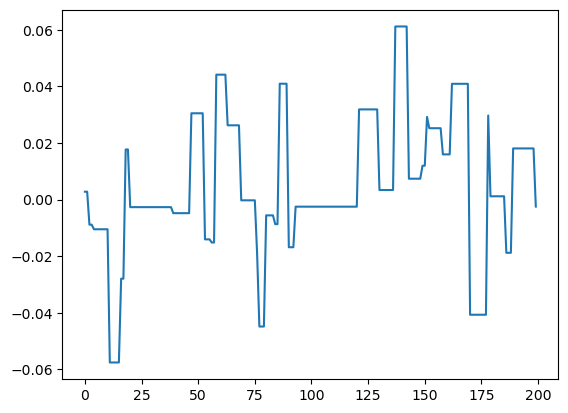

200
[ 0.0028046   0.0028046  -0.00884573 -0.00884573 -0.01046962 -0.01046962
 -0.01046962 -0.01046962 -0.01046962 -0.01046962 -0.01046962 -0.05753933
 -0.05753933 -0.05753933 -0.05753933 -0.05753933 -0.02793062 -0.02793062
  0.01771314  0.01771314 -0.00265405 -0.00265405 -0.00265405 -0.00265405
 -0.00265405 -0.00265405 -0.00265405 -0.00265405 -0.00265405 -0.00265405
 -0.00265405 -0.00265405 -0.00265405 -0.00265405 -0.00265405 -0.00265405
 -0.00265405 -0.00265405 -0.00265405 -0.00478459 -0.00478459 -0.00478459
 -0.00478459 -0.00478459 -0.00478459 -0.00478459 -0.00478459  0.03050693
  0.03050693  0.03050693  0.03050693  0.03050693  0.03050693 -0.01403589
 -0.01403589 -0.01403589 -0.01515449 -0.01515449  0.04415207  0.04415207
  0.04415207  0.04415207  0.04415207  0.02625686  0.02625686  0.02625686
  0.02625686  0.02625686  0.02625686 -0.00024567 -0.00024567 -0.00024567
 -0.00024567 -0.00024567 -0.00024567 -0.00024567 -0.01893564 -0.04483723
 -0.04483723 -0.04483723 -0.00556364 -0.0055636

In [42]:
# Generating 200 bands with random stripes

def gen_exp(w0, no_of_stripes=1):
    vec = np.random.exponential(w0 - 1, no_of_stripes) 
    if no_of_stripes == 1:
        return int(np.round(vec, 0)[0] + 1)
    else:
        return np.round(vec, 0) + 1
rand_test = gen_exp(w_0, 1)


def gen_bands(w0, length):
    bands = []
    i = 0
    while len(bands) < length:
        stripe_width = gen_exp(w0)
        magn_val = np.random.normal(0, 0.025)
        if len(bands) + stripe_width <= length:
            for j in range(stripe_width):
                bands.append(magn_val)
            i += 1
        else:
            continue
    return np.array(bands)



bands = gen_bands(w_0, 200)
# print(len(bands))


# print(bands)
plt.plot(bands)
plt.show()


print(len(bands))
print(bands)

In [43]:
def stripe_identificator(bands, index):
    indecies = []
    
    i_prev = index
    for i in range(index, len(bands)):         
        if bands[i_prev] == bands[i]:
            indecies.append(i) 
            i_prev = i
        else:
            break
    i_prev = index
    for i in range(index, 0, -1):
        if bands[i_prev] == bands[i]:
            indecies.append(i)
            i_prev = i
        else:
            break
    indecies_sorted = np.sort(np.array(indecies))
    index_low = indecies_sorted[0]
    index_high = indecies_sorted[-1]
    return index_low, index_high

def change_mag(bands):
    bands_cp = np.copy(bands)
    val = np.random.normal(0, 0.025)
    bands_length = len(bands)
    random_index = np.random.randint(bands_length)
    stripe_low, stripe_high = stripe_identificator(bands, random_index)
    for i in range(stripe_low, stripe_high + 1):
        bands_cp[i] = val
    return bands_cp, random_index

def modifiy_boundary(bands):
    bands_cp = np.copy(bands)
    bands_length = len(bands)
    random_index = np.random.randint(bands_length)
    stripe_low, stripe_high = stripe_identificator(bands, random_index)
    if random_index == stripe_low and random_index != 0:
        stripe_low2, _ = stripe_identificator(bands, random_index - 1)   # obtaining the high index of the second stripe
        new_val = np.random.normal(0, 0.025)
        for i in range(stripe_low2, stripe_high + 1):
            bands_cp[i] = new_val
    else:
        new_val1 = np.random.normal(0, 0.025)
        new_val2 = np.random.normal(0, 0.025)
        for i in range(stripe_low, random_index):
            bands_cp[i] = new_val1
        for i in range(random_index, stripe_high + 1):
            bands_cp[i] = new_val2
    return bands_cp, random_index

test = np.array([3.0, 3.0, 3.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 5.0, 5.0, 5.0, 5.0, 5.0, 3.0, 3.0, 3.0, 1.0, 2.0, 2.0, 2.0, 2.0])
index_low, index_high = stripe_identificator(test, len(test) - 1)

changed_mag, index = change_mag(test)
print(f'Array with changed value:\n{changed_mag}\n i = {index}')

changed_stripe, index = modifiy_boundary(test)
print(changed_stripe)

print(f'Array with added or removed stripe:\n{changed_stripe}\ni = {index}')

Array with changed value:
[3.         3.         3.         7.         7.         7.
 7.         7.         7.         7.         5.         5.
 5.         5.         5.         3.         3.         3.
 1.         0.05419312 0.05419312 0.05419312 0.05419312]
 i = 20
[ 3.          3.          3.          7.          7.          7.
  7.          7.          7.          7.          5.          5.
  5.          5.          5.          3.          3.          3.
  1.         -0.01534806 -0.01534806 -0.01534806 -0.0150901 ]
Array with added or removed stripe:
[ 3.          3.          3.          7.          7.          7.
  7.          7.          7.          7.          5.          5.
  5.          5.          5.          3.          3.          3.
  1.         -0.01534806 -0.01534806 -0.01534806 -0.0150901 ]
i = 22


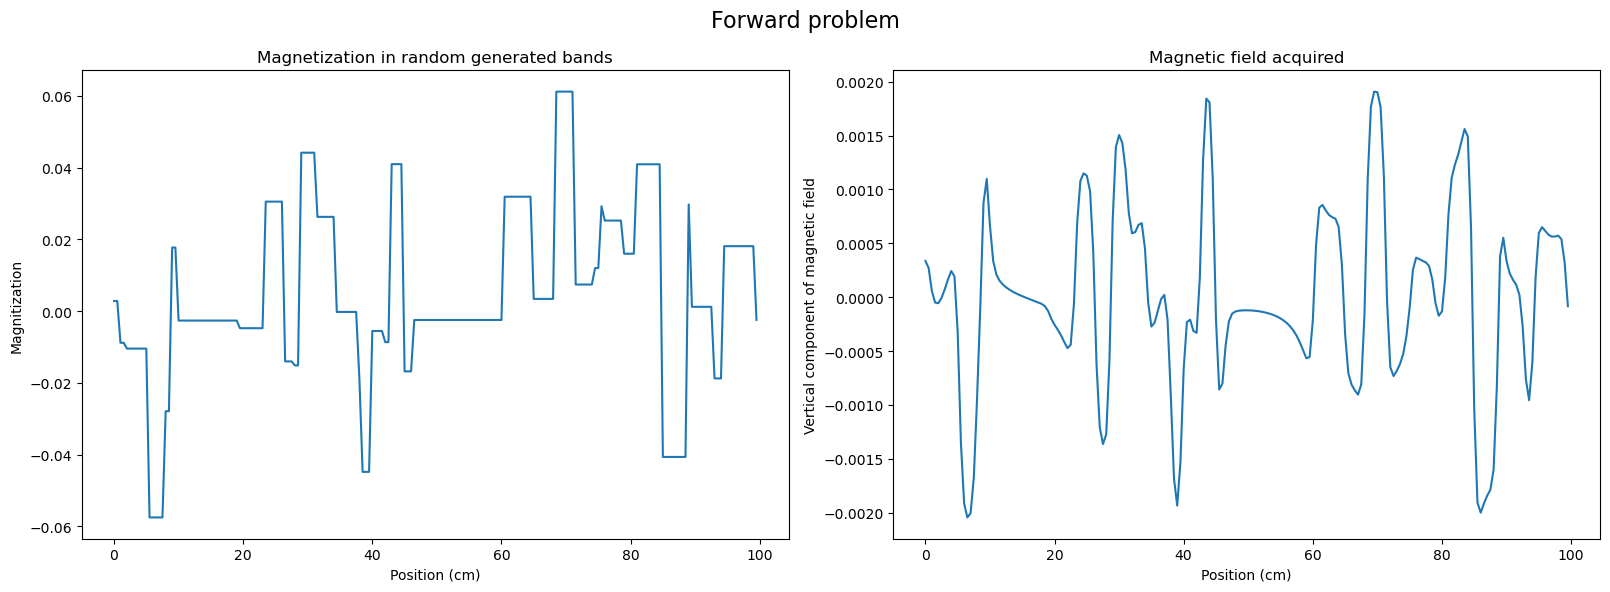

In [44]:



def g(i, j):
    '''
    Discretized G funcion. The i, j are now indecies corresponding to the
    bands array index. They can also be translated into position
    when kept in mind that bandwith = 0.5 cm
    '''
    g = -mu_0/(2*np.pi)*((i - j)**2 - h**2)/((i - j)**2 + h**2)**2
    return g

def b_field(bands):
    length = len(bands)
    gij = np.zeros((length, length))
    for i in range(length):
        for j in range(length):
            gij[i, j] = g(i, j)
    b_arr = (gij@bands)*band_width  # To check if *band_width really must be present, because I am not sure tbh (sake of units)
    return b_arr

b_fields = b_field(bands)



scale = 6
fig, axs = plt.subplots(1, 2, figsize=(scale*2.7, scale*1))
fig.suptitle('Forward problem', fontsize=16)
domain = [i*band_width for i in range(len(bands))]
for ax in axs:
    ax.set_xlabel('Position (cm)')
axs[0].set_ylabel('Magnitization')
axs[1].set_ylabel('Vertical component of magnetic field')
axs[0].set_title('Magnetization in random generated bands')
axs[0].plot(domain, bands)
axs[1].set_title('Magnetic field acquired')
axs[1].plot(domain, b_fields)

plt.tight_layout()
plt.show()